# Allen-Cahn PDE Identification

**Target PDE**
$$
\frac{1}{4}\Delta u - 5u - u^3 + u^5 = f(\mathbf{x})
$$

In [1]:
# Import dependencies and configure reproducibility.
import numpy as np
import scipy
import matplotlib.pyplot as plt
import firedrake as fd
from firedrake.pyplot import tricontourf
from wias import CPQR_solver, assemble_weak_library_rows

np.random.seed(1)
rng = np.random.default_rng(seed=1)

## Define Allen-Cahn solver

In [2]:
# Define PDE solver and synthetic forcing generator.
def solve_allen_cahn(V, f, true_coefficients):
    """
    Solve the Allen-Cahn PDE
        0.25 * Lap(u) - 5.0 * u - u^3 + u^5 = f
    with homogeneous Dirichlet boundary conditions.
    """
    u = fd.Function(V, name="u")
    v = fd.TestFunction(V)
    library_exprs, rhs = make_library_exprs(u, v, f)
    a_form = sum(
        fd.Constant(true_coefficients[name]) * expr
        for name, expr in library_exprs.items()
    )
    L_form = rhs
    bc = fd.DirichletBC(V, fd.Constant(0.0), "on_boundary")
    solver_params = {
        "snes_type": "newtonls",
        "snes_linesearch_type": "bt",
        "snes_rtol": 1e-10,
        "snes_atol": 1e-12,
        "snes_max_it": 80,
        "ksp_type": "preonly",
        "pc_type": "lu",
        "pc_factor_mat_solver_type": "mumps",
    }

    fd.solve(a_form - L_form == 0, u, bcs=bc, solver_parameters=solver_params)
    return u


def make_rhs(V, length_scale, amplitude):
    """
    Sample a smooth forcing term from a Gaussian process with
    squared-exponential covariance.
    """
    m = V.mesh()
    W = fd.VectorFunctionSpace(m, V.ufl_element())
    X = fd.assemble(fd.interpolate(m.coordinates, W))
    xs = X.dat.data_ro
    n = xs.shape[0]

    dist_sq = scipy.spatial.distance.cdist(xs, xs, "sqeuclidean")
    K = amplitude**2 * np.exp(-dist_sq / (2.0 * length_scale**2))
    K += 1e-8 * np.eye(n)

    L = np.linalg.cholesky(K)
    values = L @ rng.standard_normal(n)

    f = fd.Function(V, name="f")
    f.dat.data[:] = values
    return f

## Weak-Form Library

Define symbolic UFL expressions for candidate PDE terms. The generic `assemble_weak_library_rows` utility then assembles these terms into a linear system.

In [3]:
# Define candidate library terms and ground-truth coefficients.
def make_library_exprs(u, v, f):
    library_exprs = {
        "u_xx": - fd.inner(fd.grad(u)[0], fd.grad(v)[0]) * fd.dx,
        "u_xy": - fd.inner(fd.grad(u)[0], fd.grad(v)[1]) * fd.dx,
        "u_yx": - fd.inner(fd.grad(u)[1], fd.grad(v)[0]) * fd.dx,
        "u_yy": - fd.inner(fd.grad(u)[1], fd.grad(v)[1]) * fd.dx,
        "1": fd.Constant(1.0) * v * fd.dx,
        "u": u * v * fd.dx,
        "u^2": u**2 * v * fd.dx,
        "u^3": u**3 * v * fd.dx,
        "u^4": u**4 * v * fd.dx,
        "u^5": u**5 * v * fd.dx,
    }
    rhs = fd.inner(f, v) * fd.dx
    return library_exprs, rhs


true_coefficients = {
    "u_xx": 0.25,
    "u_xy": 0.0,
    "u_yx": 0.0,
    "u_yy": 0.25,
    "1": 0.0,
    "u": -5.0,
    "u^2": 0.0,
    "u^3": -1.0,
    "u^4": 0.0,
    "u^5": 1.0,
}

## Generate Allen-Cahn data

Create a mesh, sample a forcing field, solve the PDE, and visualize both forcing and solution.

Function space: CG(1) elements
Generating Allen-Cahn solution...


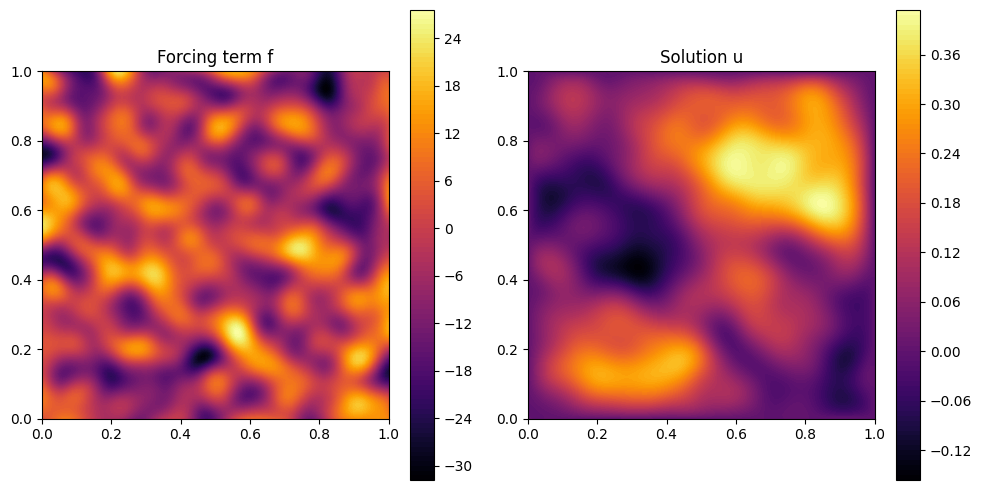

In [4]:
# Build mesh, solve PDE for one forcing realization, and visualize results.
mesh = fd.UnitSquareMesh(100, 100)
V = fd.FunctionSpace(mesh, "CG", 1)

print("Function space: CG(1) elements")

print("Generating Allen-Cahn solution...")
f = make_rhs(V, length_scale=0.05, amplitude=10.0)
u = solve_allen_cahn(V, f, true_coefficients)

fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(121)
contour_f = tricontourf(f, levels=100, axes=ax1, cmap="inferno")
ax1.set_title("Forcing term f")
ax1.set_aspect("equal")
fig.colorbar(contour_f, ax=ax1)

ax2 = fig.add_subplot(122)
contour_u = tricontourf(u, levels=100, axes=ax2, cmap="inferno")
ax2.set_title("Solution u")
ax2.set_aspect("equal")
fig.colorbar(contour_u, ax=ax2)

plt.tight_layout()
plt.show()

In [5]:
# Assemble weak-form regression matrix A and right-hand side b.
print("Building weak-form system...")
V = fd.FunctionSpace(mesh, "CG", 1)
library_exprs, rhs = make_library_exprs(u, fd.TestFunction(V), f)
bc = fd.DirichletBC(V, fd.Constant(0.0), "on_boundary")
A, b = assemble_weak_library_rows(library_exprs, rhs, bcs=bc)

print(f"System shape: {A.shape}")

Building weak-form system...
System shape: (10201, 10)


## Recover and Evaluate Coefficients

Solve the sparse regression problem with CPQR and compare recovered values to the known coefficients.

In [6]:
# Run CPQR solver and report recovered coefficients against truth.
coeffs_full = CPQR_solver(A, b)

print("Recovered coefficients:")
print(f"{'Term':<15} {'Recovered':>12} {'True':>12} {'Abs. Error':>12}")
print("-" * 55)
names = list(library_exprs.keys())
for name, coeff in zip(names, coeffs_full):
    true_c = true_coefficients.get(name, 0.0)
    error = abs(coeff - true_c)
    print(f"{name:<15} {coeff:12.6f} {true_c:12.6f} {error:12.3e}")

Recovered coefficients:
Term               Recovered         True   Abs. Error
-------------------------------------------------------
u_xx                0.250000     0.250000    1.388e-16
u_xy               -0.000000     0.000000    1.122e-15
u_yx                0.000000     0.000000    0.000e+00
u_yy                0.250000     0.250000    3.886e-16
1                   0.000000     0.000000    4.534e-15
u                  -5.000000    -5.000000    1.599e-14
u^2                -0.000000     0.000000    9.630e-15
u^3                -1.000000    -1.000000    1.288e-13
u^4                 0.000000     0.000000    1.124e-12
u^5                 1.000000     1.000000    9.125e-13
